# 01 — Exploratory Data Analysis

Chest X-ray Pneumonia dataset. Goal: understand class balance, image geometry,
intensity distributions, and data integrity **before** fixing transforms and
training settings.

In [1]:
%matplotlib inline
import hashlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd().parent
if not (ROOT / "configs" / "config.yaml").exists():
    ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))

from src.dataset import load_config

config = load_config()
frame = pd.read_csv(ROOT / config["common"]["splits_csv"], dtype={"path": str, "label": str})
frame["abs_path"] = frame["path"].map(lambda p: ROOT / p)
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
print(f"{len(frame)} rows across {frame['split'].nunique()} splits")
display(frame.head())

5824 rows across 3 splits


,path,label,split,abs_path
0,data/raw/test/NORMAL/IM-0001-0001.jpeg,NORMAL,test,C:\Users\T14s\Documents\Github\chest-xray-pneu...
1,data/raw/test/NORMAL/IM-0003-0001.jpeg,NORMAL,test,C:\Users\T14s\Documents\Github\chest-xray-pneu...
2,data/raw/test/NORMAL/IM-0005-0001.jpeg,NORMAL,test,C:\Users\T14s\Documents\Github\chest-xray-pneu...
3,data/raw/test/NORMAL/IM-0006-0001.jpeg,NORMAL,test,C:\Users\T14s\Documents\Github\chest-xray-pneu...
4,data/raw/test/NORMAL/IM-0007-0001.jpeg,NORMAL,test,C:\Users\T14s\Documents\Github\chest-xray-pneu...


## 1. Class balance

label,NORMAL,PNEUMONIA,total,pneumonia_pct
split,,,,
test,231,387,618,62.62
train,1146,3279,4425,74.10
val,202,579,781,74.14


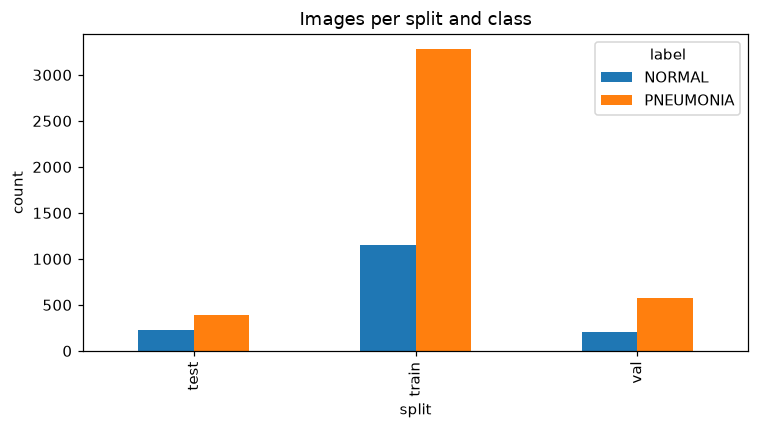

In [2]:
counts = frame.groupby(["split", "label"]).size().unstack(fill_value=0)
counts["total"] = counts.sum(axis=1)
counts["pneumonia_pct"] = (counts["PNEUMONIA"] / counts["total"] * 100).round(2)
display(counts)

ax = counts[["NORMAL", "PNEUMONIA"]].plot(kind="bar", figsize=(7, 4))
ax.set_title("Images per split and class")
ax.set_xlabel("split")
ax.set_ylabel("count")
plt.tight_layout()
plt.savefig(FIGURES / "eda_class_distribution.png")
plt.show()

## 2. Image geometry

,width,height,aspect
count,5824.0,5824.0,5824.0
mean,1327.5,970.2,1.4
std,363.5,383.3,0.3
min,384.0,127.0,0.8
25%,1056.0,688.0,1.3
50%,1280.0,886.0,1.4
75%,1560.0,1187.0,1.6
max,2916.0,2713.0,3.4


unique (width, height) pairs: 4803


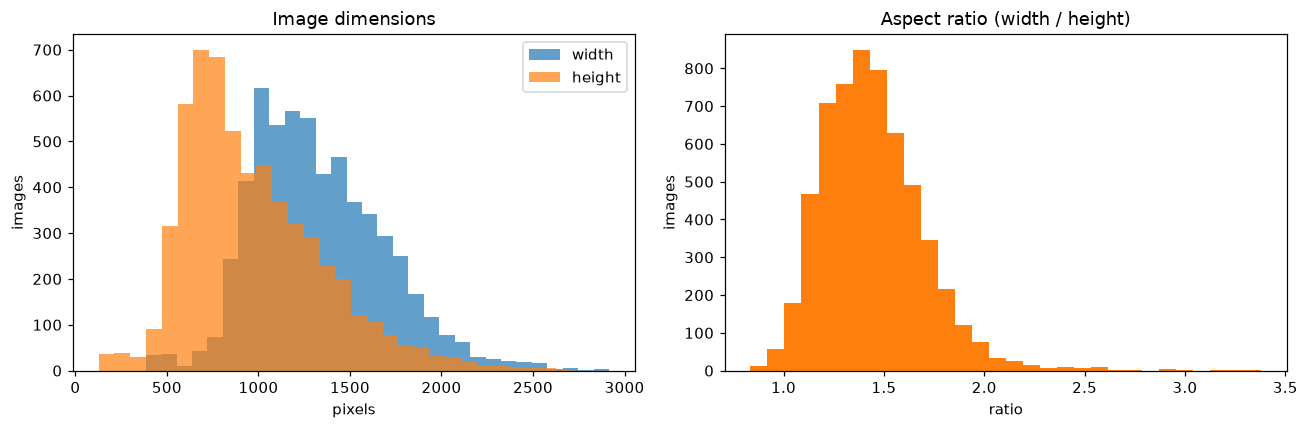

In [3]:
shapes = []
for path in frame["abs_path"]:
    with Image.open(path) as img:
        shapes.append((img.width, img.height))

frame[["width", "height"]] = pd.DataFrame(shapes, index=frame.index)
frame["aspect"] = (frame["width"] / frame["height"]).round(3)
display(frame[["width", "height", "aspect"]].describe().round(1))
print(f"unique (width, height) pairs: {len(set(shapes))}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(frame["width"], bins=30, alpha=0.7, label="width")
axes[0].hist(frame["height"], bins=30, alpha=0.7, label="height")
axes[0].set_title("Image dimensions")
axes[0].set_xlabel("pixels")
axes[0].set_ylabel("images")
axes[0].legend()
axes[1].hist(frame["aspect"], bins=30, color="tab:orange")
axes[1].set_title("Aspect ratio (width / height)")
axes[1].set_xlabel("ratio")
axes[1].set_ylabel("images")
plt.tight_layout()
plt.savefig(FIGURES / "eda_dimensions.png")
plt.show()

## 3. Pixel intensity per class

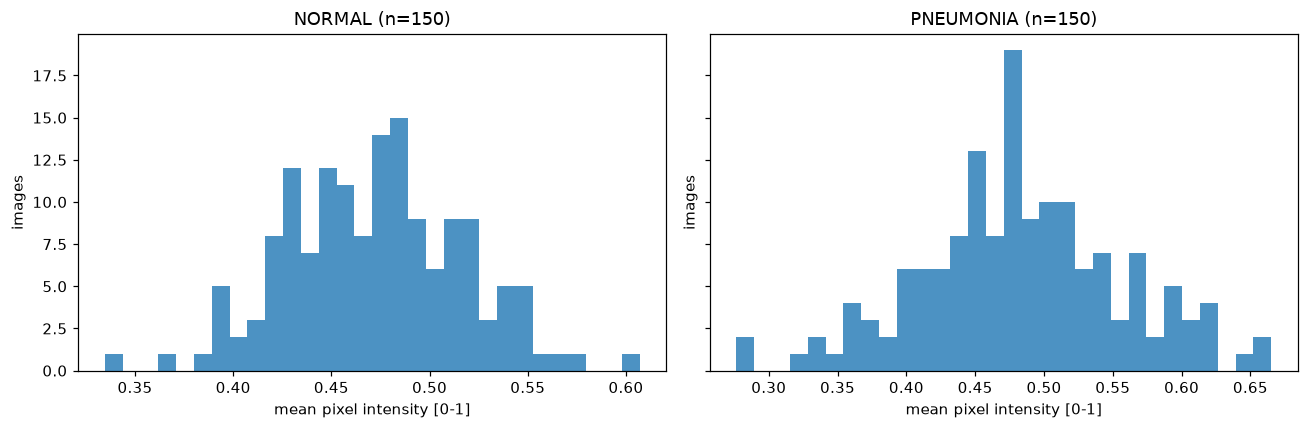

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, label in zip(axes, ("NORMAL", "PNEUMONIA")):
    sample = frame[frame["label"] == label].sample(150, random_state=42)
    means = []
    for path in sample["abs_path"]:
        with Image.open(path) as img:
            means.append(np.asarray(img.convert("L"), dtype=np.float32).mean() / 255.0)
    ax.hist(means, bins=30, alpha=0.8)
    ax.set_title(f"{label} (n={len(means)})")
    ax.set_xlabel("mean pixel intensity [0-1]")
    ax.set_ylabel("images")
plt.tight_layout()
plt.savefig(FIGURES / "eda_intensity.png")
plt.show()

## 4. Sample images

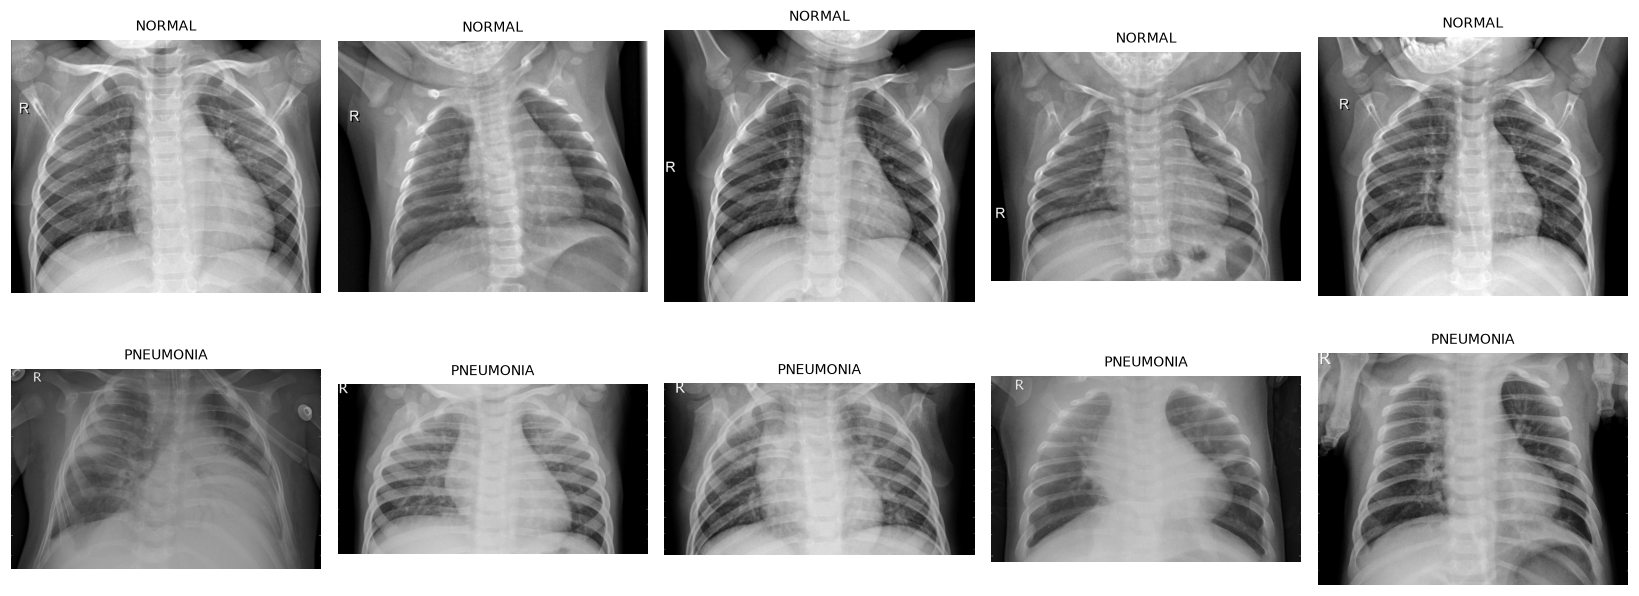

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for row, label in enumerate(("NORMAL", "PNEUMONIA")):
    sample = frame[frame["label"] == label].sample(5, random_state=7)
    for col, path in enumerate(sample["abs_path"]):
        with Image.open(path) as img:
            axes[row, col].imshow(img.convert("L"), cmap="gray")
        axes[row, col].set_title(label, fontsize=9)
        axes[row, col].axis("off")
plt.tight_layout()
plt.savefig(FIGURES / "eda_samples.png")
plt.show()

## 5. Duplicates and leakage

In [6]:
def md5(path, chunk_size=1 << 20):
    digest = hashlib.md5()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

frame["md5"] = [md5(path) for path in frame["abs_path"]]
duplicates = frame[frame.duplicated("md5", keep=False)]
print(f"duplicate images: {len(duplicates)} rows across {duplicates['md5'].nunique()} hashes")

spanning = duplicates.groupby("md5")["split"].nunique()
print(f"hashes appearing in more than one split: {int((spanning > 1).sum())}")
display(duplicates.sort_values("md5")[["path", "label", "split"]].head(10))

duplicate images: 0 rows across 0 hashes
hashes appearing in more than one split: 0


,path,label,split


## 6. Image integrity

In [7]:
unreadable = []
for path in frame["abs_path"]:
    try:
        with Image.open(path) as img:
            img.verify()
    except Exception as exc:
        unreadable.append((path.name, str(exc)))

print(f"unreadable images: {len(unreadable)}")
unreadable[:5]

unreadable images: 0


[]

## Takeaways

- **Class balance:** train/val are ~74% PNEUMONIA; test is 62.6%. Mild imbalance, so class weights are optional for the baseline.
- **Geometry:** 4803 unique (width, height) pairs; images are mostly wider than tall (mean aspect ~1.4), so a square 224x224 Resize distorts anatomy. Acceptable for a first baseline; consider letterbox/pad or center-crop later.
- **Intensity:** mean pixel intensity is similar (NORMAL ~0.46, PNEUMONIA ~0.48) with PNEUMONIA slightly wider and with a brighter tail. ImageNet mean/std normalisation is fine.
- **Duplicates / leakage:** after de-duplicating by MD5 **before** splitting (see scripts/make_splits.py), 0 duplicate rows remain and 0 hashes span more than one split. The pre-fix run found 30 duplicate hashes (9 spanning splits).
- **Integrity:** 0 unreadable images.
- **Decisions:** de-duplicated stratified split; ImageNet normalisation; square resize for the baseline; skip class weights initially.